In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss
)

# Load predictions from Part B
df = pd.read_parquet("ml4health_predictions.parquet")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (65366, 29)

Columns:
['subject_id', 'hadm_id', 'stay_id', 'intime', 'outtime', 'sex', 'race', 'insurance', 'mortality', 'age', 'heart_rate_mean', 'sbp_min', 'spo2_min', 'resp_rate_mean', 'creatinine_max', 'platelets_min', 'bun_max', 'wbc_max', 'gcs_min', 'lactate_max', 'sofa', 'charlson', 'lactate_max_measured', 'sofa_measured', 'charlson_measured', 'split', 'p_sofa', 'p_lr', 'p_xgb']


,subject_id,hadm_id,stay_id,intime,outtime,sex,race,insurance,mortality,age,...,lactate_max,sofa,charlson,lactate_max_measured,sofa_measured,charlson_measured,split,p_sofa,p_lr,p_xgb
0,10000032,29079034,39553978,2180-07-23 14:00:00,2180-07-23 23:50:47,F,White,Medicaid,0,52,...,NaN,10,3,0,1,1,train,0.298520,0.129666,0.203692
1,10000690,25860671,37081114,2150-11-02 19:37:00,2150-11-06 17:03:17,F,White,Medicare,0,86,...,NaN,5,5,0,1,1,train,0.096794,0.153617,0.126692
2,10000980,26913865,39765666,2189-06-27 08:42:00,2189-06-27 20:38:27,F,Black,Medicare,0,73,...,NaN,2,8,0,1,1,test,0.044755,0.042544,0.028553
3,10001217,24597018,37067082,2157-11-20 19:18:02,2157-11-21 22:08:00,F,White,Private,0,55,...,NaN,0,1,0,1,1,train,0.026279,0.017762,0.007963
4,10001725,25563031,31205490,2110-04-11 15:52:22,2110-04-12 23:59:56,F,White,Private,0,46,...,NaN,1,1,0,1,1,train,0.034338,0.016336,0.005937


In [2]:
print("Dataset splits:")
print(df["split"].value_counts())

print("\nMissing values:")
print(df[["race", "sex", "insurance"]].isna().sum())

print("\nPrediction columns:")
print(df[["p_sofa", "p_lr", "p_xgb"]].describe())

Dataset splits:
split
train         39219
test          13074
validation    13073
Name: count, dtype: int64

Missing values:
race            0
sex             0
insurance    1362
dtype: int64

Prediction columns:
             p_sofa          p_lr         p_xgb
count  65366.000000  65366.000000  65366.000000
mean       0.108527      0.108557      0.107824
std        0.116774      0.153297      0.171599
min        0.026279      0.001369      0.000288
25%        0.044755      0.025199      0.013164
50%        0.075218      0.053473      0.039251
75%        0.123731      0.118541      0.117187
max        0.938835      0.999932      0.995922


In [3]:
# Handle missing subgroup values
df["insurance"] = df["insurance"].fillna("Unknown")
df["race"] = df["race"].fillna("Unknown")

# Define models and sensitive attributes
MODELS = {
    "SOFA": "p_sofa",
    "LR": "p_lr",
    "XGBoost": "p_xgb"
}

SENSITIVE = ["race", "sex", "insurance"]

# Separate validation and test sets
val = df[df["split"] == "validation"].copy()
test = df[df["split"] == "test"].copy()

print("Validation size:", len(val))
print("Test size:", len(test))

# Check subgroup counts
for attr in SENSITIVE:
    print(f"\n{attr}:")
    print(test[attr].value_counts(dropna=False))

Validation size: 13073
Test size: 13074

race:
race
White       8579
Unknown     1848
Black       1214
Other        561
Hispanic     450
Asian        422
Name: count, dtype: int64

sex:
sex
M    7413
F    5661
Name: count, dtype: int64

insurance:
insurance
Medicare    6904
Private     3707
Medicaid    1830
Other        356
Unknown      277
Name: count, dtype: int64


In [4]:
# Evaluate overall model performance on the test set
results = []

for model_name, prob_col in MODELS.items():
    y_true = test["mortality"]
    y_prob = test[prob_col]

    auroc = roc_auc_score(y_true, y_prob)
    auprc = average_precision_score(y_true, y_prob)

    results.append({
        "Model": model_name,
        "AUROC": auroc,
        "AUPRC": auprc
    })

overall_results = pd.DataFrame(results)

display(overall_results.round(4))

,Model,AUROC,AUPRC
0,SOFA,0.7713,0.3568
1,LR,0.8432,0.5017
2,XGBoost,0.8799,0.5568


In [5]:
# Select model-specific thresholds using validation data
TARGET_SENSITIVITY = 0.80
thresholds = {}

for model_name, prob_col in MODELS.items():

    # Predicted risk among patients who actually died
    death_probs = val.loc[
        val["mortality"] == 1, prob_col
    ].dropna()

    # 20th percentile corresponds to approximately 80% sensitivity
    threshold = np.quantile(
        death_probs,
        1 - TARGET_SENSITIVITY
    )

    thresholds[model_name] = threshold

    # Apply the fixed threshold to the test set
    y_true = test["mortality"]
    y_pred = (test[prob_col] >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    test_sensitivity = tp / (tp + fn)

    print(
        f"{model_name}: "
        f"Threshold = {threshold:.4f}, "
        f"Test Sensitivity = {test_sensitivity:.4f}"
    )

SOFA: Threshold = 0.0752, Test Sensitivity = 0.8229
LR: Threshold = 0.0785, Test Sensitivity = 0.8278
XGBoost: Threshold = 0.0983, Test Sensitivity = 0.8038


In [6]:
def subgroup_metrics(test_df, prob_col, threshold, attr):
    results = []

    for group, data in test_df.groupby(attr):
        y_true = data["mortality"]
        y_prob = data[prob_col]
        y_pred = (y_prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        deaths = int(y_true.sum())
        n = len(data)

        results.append({
            "Group": group,
            "n": n,
            "Deaths": deaths,
            "Mortality Rate": y_true.mean(),
            "AUROC": roc_auc_score(y_true, y_prob)
                     if y_true.nunique() == 2 else np.nan,
            "AUPRC": average_precision_score(y_true, y_prob)
                     if deaths > 0 else np.nan,
            "FNR": fn / (fn + tp) if (fn + tp) > 0 else np.nan,
            "FPR": fp / (fp + tn) if (fp + tn) > 0 else np.nan,
            "Brier": brier_score_loss(y_true, y_prob),
            "Calibration-in-the-large": y_prob.mean() - y_true.mean(),
            "Unstable_n": n < 500,
            "Unstable_deaths": deaths < 50,
            "Unstable": (n < 500) or (deaths < 50)
        })

    return pd.DataFrame(results)

In [7]:
xgb_race = subgroup_metrics(
    test, "p_xgb", thresholds["XGBoost"], "race"
)

xgb_sex = subgroup_metrics(
    test, "p_xgb", thresholds["XGBoost"], "sex"
)

xgb_insurance = subgroup_metrics(
    test, "p_xgb", thresholds["XGBoost"], "insurance"
)

print("=== XGBoost: Race ===")
display(xgb_race.round(4))

print("=== XGBoost: Sex ===")
display(xgb_sex.round(4))

print("=== XGBoost: Insurance ===")
display(xgb_insurance.round(4))

=== XGBoost: Race ===


,Group,n,Deaths,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,Asian,422,44,0.1043,0.8641,0.4326,0.2500,0.2275,0.0751,0.0103,True,True,True
1,Black,1214,109,0.0898,0.8870,0.5084,0.1743,0.2281,0.0613,0.0196,False,False,False
2,Hispanic,450,34,0.0756,0.9028,0.5157,0.1765,0.1779,0.0493,0.0137,True,True,True
3,Other,561,51,0.0909,0.8991,0.5719,0.1765,0.1961,0.0567,0.0047,False,False,False
4,Unknown,1848,350,0.1894,0.8770,0.6757,0.1943,0.2316,0.1046,-0.0552,False,False,False
5,White,8579,829,0.0966,0.8781,0.5367,0.1990,0.2236,0.0621,0.0070,False,False,False


=== XGBoost: Sex ===


,Group,n,Deaths,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,F,5661,613,0.1083,0.8735,0.5457,0.2039,0.2355,0.0687,0.0020,False,False,False
1,M,7413,804,0.1085,0.8848,0.5657,0.1903,0.2123,0.0670,-0.0022,False,False,False


=== XGBoost: Insurance ===


,Group,n,Deaths,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,Medicaid,1830,166,0.0907,0.9037,0.6174,0.1988,0.1755,0.0526,0.0010,False,False,False
1,Medicare,6904,906,0.1312,0.8565,0.5456,0.1766,0.2904,0.0829,0.0009,False,False,False
2,Other,356,22,0.0618,0.9216,0.5801,0.1364,0.1647,0.0383,0.0127,True,True,True
3,Private,3707,261,0.0704,0.8995,0.5103,0.2490,0.1373,0.0470,0.0025,False,False,False
4,Unknown,277,62,0.2238,0.9247,0.8205,0.2742,0.1395,0.1064,-0.0986,True,False,True


In [8]:
def calculate_fairness_gaps(subgroup_df):
    auroc_gap = subgroup_df["AUROC"].max() - subgroup_df["AUROC"].min()
    fnr_gap = subgroup_df["FNR"].max() - subgroup_df["FNR"].min()
    fpr_gap = subgroup_df["FPR"].max() - subgroup_df["FPR"].min()

    # Equalized Odds: maximum difference in TPR or FPR
    eo_gap = max(fnr_gap, fpr_gap)

    return {
        "AUROC Gap": auroc_gap,
        "FNR Gap": fnr_gap,
        "FPR Gap": fpr_gap,
        "EO Gap": eo_gap,
        "AUROC Flag": auroc_gap > 0.05,
        "FNR Flag": fnr_gap > 0.05,
        "Fairness Concern": (auroc_gap > 0.05) or (fnr_gap > 0.05)
    }

In [9]:
gap_results = []

for model_name, prob_col in MODELS.items():
    for attr in SENSITIVE:

        subgroup_df = subgroup_metrics(
            test,
            prob_col,
            thresholds[model_name],
            attr
        )

        gaps = calculate_fairness_gaps(subgroup_df)

        gap_results.append({
            "Model": model_name,
            "Attribute": attr,
            **gaps
        })

fairness_gaps = pd.DataFrame(gap_results)

display(fairness_gaps.round(4))

,Model,Attribute,AUROC Gap,FNR Gap,FPR Gap,EO Gap,AUROC Flag,FNR Flag,Fairness Concern
0,SOFA,race,0.0581,0.1176,0.0922,0.1176,True,True,True
1,SOFA,sex,0.0005,0.0328,0.0664,0.0664,False,False,False
2,SOFA,insurance,0.0955,0.0788,0.1914,0.1914,True,True,True
3,LR,race,0.0494,0.0286,0.0725,0.0725,False,False,False
4,LR,sex,0.0146,0.0243,0.0036,0.0243,False,False,False
5,LR,insurance,0.1020,0.2041,0.2914,0.2914,True,True,True
6,XGBoost,race,0.0387,0.0757,0.0538,0.0757,False,True,True
7,XGBoost,sex,0.0113,0.0136,0.0233,0.0233,False,False,False
8,XGBoost,insurance,0.0682,0.1378,0.1532,0.1532,True,True,True


In [10]:
def bootstrap_fairness(test_df, prob_col, threshold, attr,
                       n_boot=1000, seed=42):

    rng = np.random.default_rng(seed)
    boot_results = []

    groups = {
        group: data
        for group, data in test_df.groupby(attr)
    }

    for _ in range(n_boot):
        samples = []

        for group, data in groups.items():
            indices = rng.integers(0, len(data), len(data))
            samples.append(data.iloc[indices])

        boot_df = pd.concat(samples, ignore_index=True)

        subgroup_df = subgroup_metrics(
            boot_df, prob_col, threshold, attr
        )

        gaps = calculate_fairness_gaps(subgroup_df)
        boot_results.append(gaps)

    return pd.DataFrame(boot_results)

In [11]:
bootstrap_results = []

for attr in SENSITIVE:

    boot_df = bootstrap_fairness(
        test,
        "p_xgb",
        thresholds["XGBoost"],
        attr,
        n_boot=1000,
        seed=42
    )

    point = fairness_gaps.loc[
        (fairness_gaps["Model"] == "XGBoost") &
        (fairness_gaps["Attribute"] == attr)
    ].iloc[0]

    for metric in ["AUROC Gap", "FNR Gap"]:

        lower, upper = np.percentile(
            boot_df[metric].dropna(),
            [2.5, 97.5]
        )

        criterion = 0.05

        bootstrap_results.append({
            "Model": "XGBoost",
            "Attribute": attr,
            "Metric": metric,
            "Point Estimate": point[metric],
            "CI Lower": lower,
            "CI Upper": upper,
            "Exceeds Criterion": point[metric] > criterion,
            "CI Lower > Criterion": lower > criterion
        })

bootstrap_summary = pd.DataFrame(bootstrap_results)

display(bootstrap_summary.round(4))

,Model,Attribute,Metric,Point Estimate,CI Lower,CI Upper,Exceeds Criterion,CI Lower > Criterion
0,XGBoost,race,AUROC Gap,0.0387,0.0219,0.1142,False,False
1,XGBoost,race,FNR Gap,0.0757,0.0493,0.2835,True,False
2,XGBoost,sex,AUROC Gap,0.0113,0.0007,0.0284,False,False
3,XGBoost,sex,FNR Gap,0.0136,0.0009,0.0546,False,False
4,XGBoost,insurance,AUROC Gap,0.0682,0.0506,0.1148,True,True
5,XGBoost,insurance,FNR Gap,0.1378,0.0673,0.3077,True,True


Step 5.4 — LR Bootstrap Confidence Intervals

In [12]:
# Bootstrap confidence intervals for Logistic Regression
lr_bootstrap_results = []

for attr in SENSITIVE:

    boot_df = bootstrap_fairness(
        test,
        "p_lr",
        thresholds["LR"],
        attr,
        n_boot=1000,
        seed=42
    )

    point = fairness_gaps.loc[
        (fairness_gaps["Model"] == "LR") &
        (fairness_gaps["Attribute"] == attr)
    ].iloc[0]

    for metric in ["AUROC Gap", "FNR Gap"]:

        valid_values = boot_df[metric].dropna()

        lower, upper = np.percentile(
            valid_values,
            [2.5, 97.5]
        )

        lr_bootstrap_results.append({
            "Model": "LR",
            "Attribute": attr,
            "Metric": metric,
            "Point Estimate": point[metric],
            "CI Lower": lower,
            "CI Upper": upper,
            "Valid Bootstraps": len(valid_values),
            "Exceeds Criterion": point[metric] > 0.05,
            "CI Lower > Criterion": lower > 0.05
        })

lr_bootstrap_summary = pd.DataFrame(lr_bootstrap_results)

display(lr_bootstrap_summary.round(4))

,Model,Attribute,Metric,Point Estimate,CI Lower,CI Upper,Valid Bootstraps,Exceeds Criterion,CI Lower > Criterion
0,LR,race,AUROC Gap,0.0494,0.0305,0.1284,1000,False,False
1,LR,race,FNR Gap,0.0286,0.0462,0.2349,1000,False,False
2,LR,sex,AUROC Gap,0.0146,0.0007,0.0358,1000,False,False
3,LR,sex,FNR Gap,0.0243,0.0011,0.0622,1000,False,False
4,LR,insurance,AUROC Gap,0.1020,0.0600,0.1506,1000,True,True
5,LR,insurance,FNR Gap,0.2041,0.1199,0.3651,1000,True,True


In [13]:
# Combine bootstrap results
bootstrap_comparison = pd.concat(
    [bootstrap_summary, lr_bootstrap_summary],
    ignore_index=True
)

display(bootstrap_comparison.round(4))

,Model,Attribute,Metric,Point Estimate,CI Lower,CI Upper,Exceeds Criterion,CI Lower > Criterion,Valid Bootstraps
0,XGBoost,race,AUROC Gap,0.0387,0.0219,0.1142,False,False,NaN
1,XGBoost,race,FNR Gap,0.0757,0.0493,0.2835,True,False,NaN
2,XGBoost,sex,AUROC Gap,0.0113,0.0007,0.0284,False,False,NaN
3,XGBoost,sex,FNR Gap,0.0136,0.0009,0.0546,False,False,NaN
4,XGBoost,insurance,AUROC Gap,0.0682,0.0506,0.1148,True,True,NaN
5,XGBoost,insurance,FNR Gap,0.1378,0.0673,0.3077,True,True,NaN
6,LR,race,AUROC Gap,0.0494,0.0305,0.1284,False,False,1000.0
7,LR,race,FNR Gap,0.0286,0.0462,0.2349,False,False,1000.0
8,LR,sex,AUROC Gap,0.0146,0.0007,0.0358,False,False,1000.0
9,LR,sex,FNR Gap,0.0243,0.0011,0.0622,False,False,1000.0


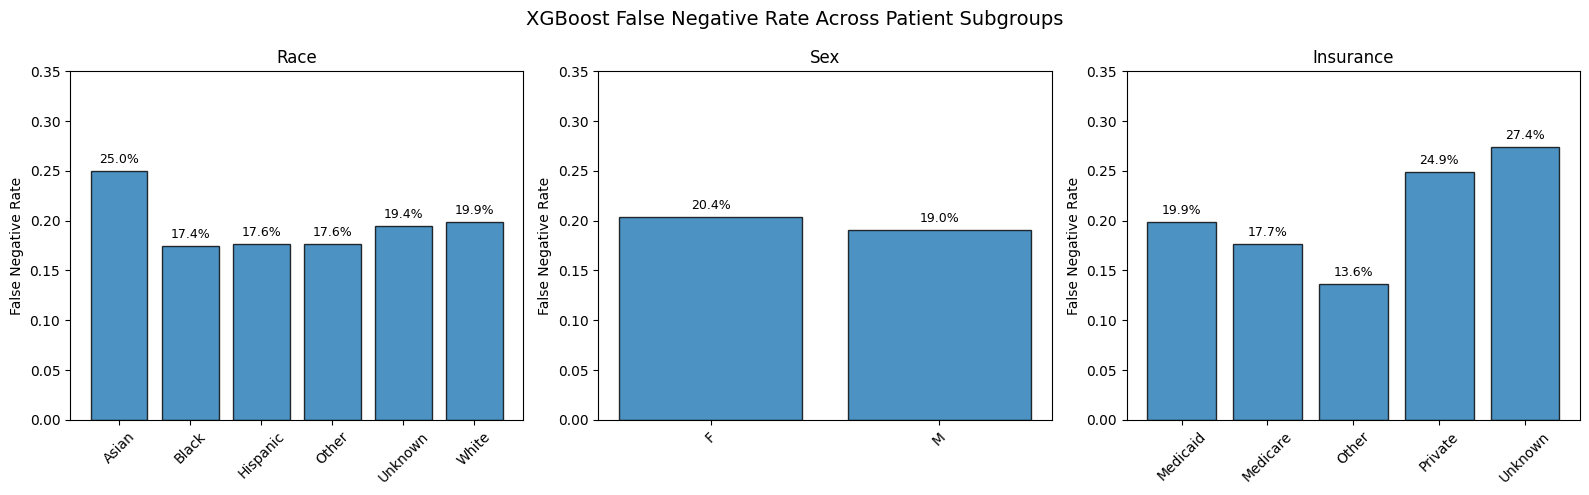

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

subgroup_tables = {
    "Race": xgb_race,
    "Sex": xgb_sex,
    "Insurance": xgb_insurance
}

for ax, (attribute, data) in zip(axes, subgroup_tables.items()):

    ax.bar(
        data["Group"],
        data["FNR"],
        edgecolor="black",
        alpha=0.8
    )

    ax.set_title(attribute)
    ax.set_ylabel("False Negative Rate")
    ax.set_ylim(0, 0.35)

    ax.tick_params(axis="x", rotation=45)

    for i, value in enumerate(data["FNR"]):
        ax.text(
            i,
            value + 0.008,
            f"{value:.1%}",
            ha="center",
            fontsize=9
        )

fig.suptitle(
    "XGBoost False Negative Rate Across Patient Subgroups",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "figure1_xgb_fnr.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

AUROC Across Patient Subgroups

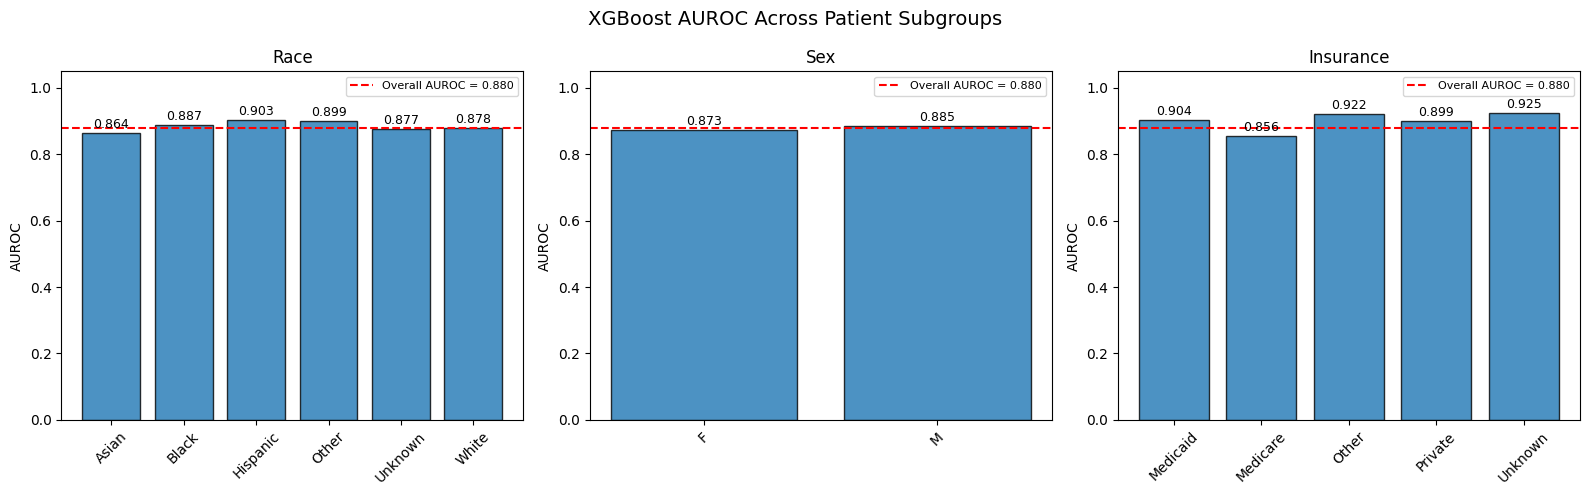

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

subgroup_tables = {
    "Race": xgb_race,
    "Sex": xgb_sex,
    "Insurance": xgb_insurance
}

overall_auroc = roc_auc_score(
    test["mortality"],
    test["p_xgb"]
)

for ax, (attribute, data) in zip(axes, subgroup_tables.items()):

    ax.bar(
        data["Group"],
        data["AUROC"],
        edgecolor="black",
        alpha=0.8
    )

    # Overall model performance reference
    ax.axhline(
        overall_auroc,
        color="red",
        linestyle="--",
        label=f"Overall AUROC = {overall_auroc:.3f}"
    )

    ax.set_title(attribute)
    ax.set_ylabel("AUROC")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=45)

    for i, value in enumerate(data["AUROC"]):
        ax.text(
            i,
            value + 0.015,
            f"{value:.3f}",
            ha="center",
            fontsize=9
        )

    ax.legend(fontsize=8)

fig.suptitle(
    "XGBoost AUROC Across Patient Subgroups",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "figure2_xgb_auroc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Fairness Gap Comparison with 95% CI

In [16]:
# Prepare plotting table
plot_df = bootstrap_comparison.copy()

# Only keep LR and XGBoost
plot_df = plot_df[plot_df["Model"].isin(["LR", "XGBoost"])].copy()

# Create a label for the x-axis
plot_df["Label"] = plot_df["Model"] + " - " + plot_df["Attribute"]

# Sort order
attribute_order = {"race": 0, "sex": 1, "insurance": 2}
model_order = {"LR": 0, "XGBoost": 1}
metric_order = {"AUROC Gap": 0, "FNR Gap": 1}

plot_df["attr_order"] = plot_df["Attribute"].map(attribute_order)
plot_df["model_order"] = plot_df["Model"].map(model_order)
plot_df["metric_order"] = plot_df["Metric"].map(metric_order)

plot_df = plot_df.sort_values(
    ["metric_order", "attr_order", "model_order"]
).reset_index(drop=True)

display(plot_df[[
    "Model", "Attribute", "Metric",
    "Point Estimate", "CI Lower", "CI Upper"
]].round(4))

,Model,Attribute,Metric,Point Estimate,CI Lower,CI Upper
0,LR,race,AUROC Gap,0.0494,0.0305,0.1284
1,XGBoost,race,AUROC Gap,0.0387,0.0219,0.1142
2,LR,sex,AUROC Gap,0.0146,0.0007,0.0358
3,XGBoost,sex,AUROC Gap,0.0113,0.0007,0.0284
4,LR,insurance,AUROC Gap,0.1020,0.0600,0.1506
5,XGBoost,insurance,AUROC Gap,0.0682,0.0506,0.1148
6,LR,race,FNR Gap,0.0286,0.0462,0.2349
7,XGBoost,race,FNR Gap,0.0757,0.0493,0.2835
8,LR,sex,FNR Gap,0.0243,0.0011,0.0622
9,XGBoost,sex,FNR Gap,0.0136,0.0009,0.0546


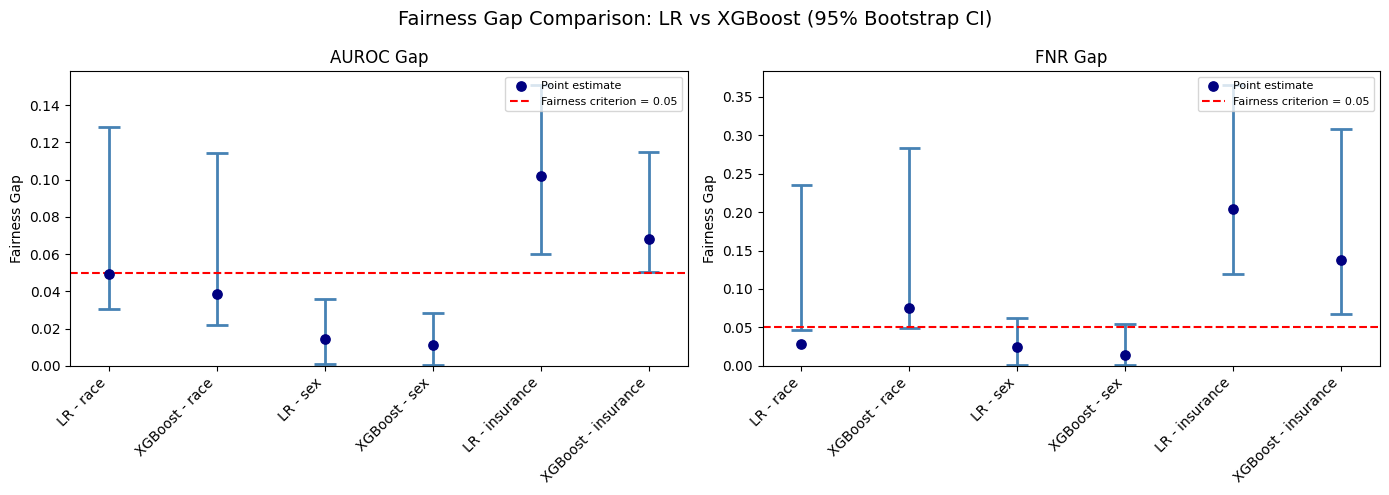

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics = ["AUROC Gap", "FNR Gap"]

for ax, metric in zip(axes, metrics):

    data = plot_df[plot_df["Metric"] == metric].copy()

    x = np.arange(len(data))
    y = data["Point Estimate"].to_numpy(dtype=float)
    lower = data["CI Lower"].to_numpy(dtype=float)
    upper = data["CI Upper"].to_numpy(dtype=float)

    # Draw bootstrap confidence intervals independently
    for i in range(len(data)):
        ax.vlines(
            x[i], lower[i], upper[i],
            color="steelblue",
            linewidth=2
        )

        ax.hlines(
            [lower[i], upper[i]],
            x[i] - 0.1,
            x[i] + 0.1,
            color="steelblue",
            linewidth=2
        )

    # Plot original point estimates separately
    ax.scatter(
        x, y,
        color="navy",
        s=45,
        zorder=3,
        label="Point estimate"
    )

    # Fairness threshold
    ax.axhline(
        0.05,
        color="red",
        linestyle="--",
        label="Fairness criterion = 0.05"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        data["Label"],
        rotation=45,
        ha="right"
    )

    ax.set_ylabel("Fairness Gap")
    ax.set_title(metric)
    ax.set_ylim(bottom=0)

    ax.legend(fontsize=8)

fig.suptitle(
    "Fairness Gap Comparison: LR vs XGBoost (95% Bootstrap CI)",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "figure3_fairness_gap_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Part C Fairness Audit: Results and Interpretation

**Overall performance.** On the held-out test set (n = 13,074), XGBoost achieved the highest discrimination (AUROC = 0.880), followed by Logistic Regression (AUROC = 0.843) and SOFA (AUROC = 0.771). Model-specific operating thresholds were selected on the validation set to target 80% sensitivity and applied unchanged to the test set.

**Fairness across patient subgroups.** Insurance status showed the largest fairness disparities for LR and XGBoost. XGBoost demonstrated an insurance AUROC gap of 0.0682 (95% bootstrap CI: 0.0506–0.1148) and an FNR gap of 0.1378 (95% CI: 0.0673–0.3077). LR showed larger insurance disparities, with an AUROC gap of 0.1020 (95% CI: 0.0600–0.1506) and an FNR gap of 0.2041 (95% CI: 0.1199–0.3651). All four intervals had lower bounds above the pre-specified fairness criterion of 0.05.

**Race and sex.** XGBoost's race FNR gap was 0.0757 (95% CI: 0.0493–0.2835), exceeding the criterion at the point-estimate level, but not across the entire confidence interval. The Asian subgroup had only 44 observed deaths, limiting estimate stability. For sex, neither LR nor XGBoost exceeded the pre-specified AUROC or FNR gap criterion at the point-estimate level.

**Subgroup stability.** Consistent with the original proposal, subgroups with fewer than 500 patients were flagged as unstable. An additional criterion of fewer than 50 observed deaths was applied to identify potentially unreliable FNR estimates. Subgroups meeting either criterion were retained in the analysis but interpreted with caution. These thresholds were used as stability flags rather than exclusion criteria.

**Interpretation and limitations.** Better overall discrimination did not eliminate subgroup performance disparities. The insurance results indicate the strongest evidence of disparities exceeding the pre-specified thresholds, although the gap estimates and percentile bootstrap intervals may be affected by small subgroup event counts and selection of the maximum and minimum subgroup values. These observational findings do not establish that insurance status causes differences in model performance.

### Handoff to Part D Fairness Mitigation

The mitigation stage should prioritize insurance-related disparities, particularly false-negative rates. Model-specific thresholds must be selected or adjusted using validation data only, with the test set reserved for final evaluation. Any mitigation should be assessed for changes in subgroup FNR and AUROC gaps, overall sensitivity, and potential increases in false positives. Small subgroups and missing demographic information should remain visible in the evaluation rather than being excluded.

### Declaration of Generative AI Use

I used ChatGPT to assist with explaining statistical concepts, developing and debugging Python code, and interpreting the fairness audit results. The analysis was executed in Google Colab using the team's prediction dataset. I reviewed the outputs, checked the calculated metrics against the project plan, and evaluated the findings. Generative AI did not independently access the team's Colab environment or execute the submitted analysis.

# --------

# Part D

Before applying mitigation, we retain the original XGBoost insurance subgroup results from Part C as the baseline. The same validation-derived decision threshold and held-out test set will be used throughout Part D to ensure a valid before–after comparison.

In [18]:
# Preserve the original Part C XGBoost insurance results
xgb_insurance_baseline = xgb_insurance.copy()

# Baseline fairness gaps
baseline_auroc_gap = (xgb_insurance_baseline["AUROC"].max() - xgb_insurance_baseline["AUROC"].min())
baseline_fnr_gap = (xgb_insurance_baseline["FNR"].max() - xgb_insurance_baseline["FNR"].min())
baseline_fpr_gap = (xgb_insurance_baseline["FPR"].max() - xgb_insurance_baseline["FPR"].min())

baseline_eo_gap = max(baseline_fnr_gap, baseline_fpr_gap)
# Overall test-set performance before mitigation
baseline_auroc = roc_auc_score(test["mortality"], test["p_xgb"])

baseline_auprc = average_precision_score(test["mortality"], test["p_xgb"])
baseline_pred = (test["p_xgb"] >= thresholds["XGBoost"]).astype(int)
tn, fp, fn, tp = confusion_matrix(
  test["mortality"],
  baseline_pred,
  labels=[0, 1]
).ravel()
baseline_sensitivity = tp / (tp + fn)
baseline_fpr = fp / (fp + tn)
# Summary table for later before-after comparison
baseline_summary = pd.DataFrame({
  "Metric": [
    "AUROC",
    "AUPRC",
    "Overall Sensitivity",
    "Overall FPR",
    "Insurance AUROC Gap",
    "Insurance FNR Gap",
    "Insurance FPR Gap",
    "Equalized Odds Gap"
  ],
  "Before Mitigation": [
    baseline_auroc,
    baseline_auprc,
    baseline_sensitivity,
    baseline_fpr,
    baseline_auroc_gap,
    baseline_fnr_gap,
    baseline_fpr_gap,
    baseline_eo_gap
  ]
})

print("=== XGBoost baseline before mitigation ===")
print(f"Decision threshold: {thresholds['XGBoost']:.4f}")
display(xgb_insurance_baseline.round(4))
display(baseline_summary.round(4))

=== XGBoost baseline before mitigation ===
Decision threshold: 0.0983


,Group,n,Deaths,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,Medicaid,1830,166,0.0907,0.9037,0.6174,0.1988,0.1755,0.0526,0.0010,False,False,False
1,Medicare,6904,906,0.1312,0.8565,0.5456,0.1766,0.2904,0.0829,0.0009,False,False,False
2,Other,356,22,0.0618,0.9216,0.5801,0.1364,0.1647,0.0383,0.0127,True,True,True
3,Private,3707,261,0.0704,0.8995,0.5103,0.2490,0.1373,0.0470,0.0025,False,False,False
4,Unknown,277,62,0.2238,0.9247,0.8205,0.2742,0.1395,0.1064,-0.0986,True,False,True


,Metric,Before Mitigation
0,AUROC,0.8799
1,AUPRC,0.5568
2,Overall Sensitivity,0.8038
3,Overall FPR,0.2224
4,Insurance AUROC Gap,0.0682
5,Insurance FNR Gap,0.1378
6,Insurance FPR Gap,0.1532
7,Equalized Odds Gap,0.1532


## Mitigation 1: insurance-specific threshold adjustment

This post-processing strategy was motivated by the equal-opportunity framework
of Hardt et al., in which group-specific decision thresholds can be used to
reduce disparities in true-positive rates. Here, thresholds were selected to
target approximately 80% sensitivity within each insurance group.

**Reference:**

Hardt M, Price E, Srebro N. Equality of Opportunity in Supervised Learning. arXiv preprint arXiv:1610.02413. 2016.

### Select insurance-specific thresholds using VALIDATION data only

For each insurance group, we calculate the predicted probability of death for patients in that group and then take the 20th percentile. This means that approximately 80% of patients who die will have a predicted probability of death above this threshold, corresponding to about 80% sensitivity

In [19]:
TARGET_SENSITIVITY = 0.80
insurance_thresholds = {}

for group, data in val.groupby("insurance"):
  # Predicted probabilities among patients who died within this insurance group
  death_probs = data.loc[data["mortality"] == 1, "p_xgb"].dropna()
  # Retain all groups, including small and Unknown groups
  if len(death_probs) == 0:
    insurance_thresholds[group] = thresholds["XGBoost"]
    continue
  # Choose the threshold corresponding to approximately 80% sensitivity within this insurance group
  group_threshold = np.quantile(death_probs, 1 - TARGET_SENSITIVITY)
  insurance_thresholds[group] = group_threshold

insurance_thresholds = pd.Series(
  insurance_thresholds,
  name="Adjusted Threshold"
).sort_index()

print("=== Insurance-specific thresholds selected on validation set ===")
display(insurance_thresholds.round(4))

=== Insurance-specific thresholds selected on validation set ===


,Adjusted Threshold
Medicaid,0.0817
Medicare,0.1036
Other,0.0900
Private,0.0918
Unknown,0.1576


### Check the adjusted thresholds on validation data

We want to confirm whether, after the adjustment, the sensitivity for each insurance group is indeed close to 80%, meaning the FNR is close to 20%.

In [20]:
validation_threshold_check = []

for group, data in val.groupby("insurance"):
  threshold = insurance_thresholds[group]
  y_true = data["mortality"].astype(int)
  y_pred = (data["p_xgb"] >= threshold).astype(int)

  tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

  sensitivity = (tp / (tp + fn) if (tp + fn) > 0 else np.nan)
  fnr = (fn / (fn + tp) if (fn + tp) > 0 else np.nan)
  fpr = (fp / (fp + tn) if (fp + tn) > 0 else np.nan)

  validation_threshold_check.append({
    "Group": group,
    "n": len(data),
    "Deaths": int(y_true.sum()),
    "Threshold": threshold,
    "Sensitivity": sensitivity,
    "FNR": fnr,
    "FPR": fpr
  })

validation_threshold_check = pd.DataFrame(validation_threshold_check)

print("=== Validation performance after threshold adjustment ===")
display(validation_threshold_check.sort_values("Group").round(4))

=== Validation performance after threshold adjustment ===


,Group,n,Deaths,Threshold,Sensitivity,FNR,FPR
0,Medicaid,1882,194,0.0817,0.7990,0.2010,0.2032
1,Medicare,6925,900,0.1036,0.8000,0.2000,0.2873
2,Other,361,26,0.0900,0.8077,0.1923,0.1373
3,Private,3623,230,0.0918,0.8000,0.2000,0.1488
4,Unknown,282,67,0.1576,0.7910,0.2090,0.0419


### Apply fixed insurance-specific thresholds to the held-out TEST set

Since the existing `subgroup_metrics()` function can only accept a single uniform threshold, we'll write a separate function here so that different insurance groups can use their own thresholds.

In [41]:
def subgroup_metrics_adjusted_thresholds(test_df, prob_col, threshold_dict, attr):
  results = []
  for group, data in test_df.groupby(attr):
    y_true = data["mortality"].astype(int)
    y_prob = data[prob_col]
    # Use the threshold selected for this group
    # from the validation set
    threshold = threshold_dict[group]
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    deaths = int(y_true.sum())
    n = len(data)
    results.append({
      "Group": group,
      "n": n,
      "Deaths": deaths,
      "Threshold": threshold,
      "Mortality Rate": y_true.mean(),
      "AUROC": (roc_auc_score(y_true, y_prob) if y_true.nunique() == 2 else np.nan),
      "AUPRC": (average_precision_score(y_true, y_prob) if deaths > 0 else np.nan),
      "FNR": (fn / (fn + tp) if (fn + tp) > 0 else np.nan),
      "FPR": (fp / (fp + tn) if (fp + tn) > 0 else np.nan),
      "Brier": brier_score_loss(y_true, y_prob),
      "Calibration-in-the-large": y_prob.mean() - y_true.mean(),
      # Same stability rule as Part C
      "Unstable_n": n < 500,
      "Unstable_deaths": deaths < 50,
      "Unstable": (n < 500) or (deaths < 50)
  })

  return pd.DataFrame(results)

xgb_insurance_threshold_adj = (
  subgroup_metrics_adjusted_thresholds(
    test_df=test,
    prob_col="p_xgb",
    threshold_dict=insurance_thresholds,
    attr="insurance"
  )
)

print("=== XGBoost after insurance-specific threshold adjustment ===")
display(xgb_insurance_threshold_adj.sort_values("Group").round(4))

=== XGBoost after insurance-specific threshold adjustment ===


,Group,n,Deaths,Threshold,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,Medicaid,1830,166,0.0817,0.0907,0.9037,0.6174,0.1566,0.2115,0.0526,0.0010,False,False,False
1,Medicare,6904,906,0.1036,0.1312,0.8565,0.5456,0.1898,0.2763,0.0829,0.0009,False,False,False
2,Other,356,22,0.0900,0.0618,0.9216,0.5801,0.1364,0.1737,0.0383,0.0127,True,True,True
3,Private,3707,261,0.0918,0.0704,0.8995,0.5103,0.2375,0.1486,0.0470,0.0025,False,False,False
4,Unknown,277,62,0.1576,0.2238,0.9247,0.8205,0.3226,0.0744,0.1064,-0.0986,True,False,True


### Calculate fairness gaps after mitigation

In [42]:
threshold_adj_gaps = calculate_fairness_gaps(xgb_insurance_threshold_adj)

print("=== Fairness gaps after threshold adjustment ===")
for metric, value in threshold_adj_gaps.items():
  print(f"{metric}: {value:.4f}")

=== Fairness gaps after threshold adjustment ===
AUROC Gap: 0.0682
FNR Gap: 0.1862
FPR Gap: 0.2018
EO Gap: 0.2018
AUROC Flag: 1.0000
FNR Flag: 1.0000
Fairness Concern: 1.0000


### Overall test performance after threshold adjustment

In [43]:
adjusted_pred = pd.Series(index=test.index, dtype=int)

for group in test["insurance"].unique():
    group_mask = (test["insurance"] == group)
    adjusted_pred.loc[group_mask] = (test.loc[group_mask, "p_xgb"] >= insurance_thresholds[group]).astype(int)

adjusted_pred = adjusted_pred.astype(int)
tn, fp, fn, tp = confusion_matrix(test["mortality"], adjusted_pred, labels=[0, 1]).ravel()
threshold_adj_sensitivity = (tp / (tp + fn))
threshold_adj_fpr = (fp / (fp + tn))

print("=== Overall performance after threshold adjustment ===")
print(f"Sensitivity: {threshold_adj_sensitivity:.4f}")
print(f"FPR:         {threshold_adj_fpr:.4f}")

=== Overall performance after threshold adjustment ===
Sensitivity: 0.8003
FPR:         0.2226


### Evaluate reduction in the primary FNR gap

The primary mitigation target was the insurance FNR gap. Mitigation was
considered successful if this gap was reduced by at least 50% while overall
AUROC decreased by less than 0.02.

In [44]:
fnr_gap_reduction = (baseline_fnr_gap - threshold_adj_gaps["FNR Gap"])
fnr_gap_reduction_pct = (fnr_gap_reduction / baseline_fnr_gap)

print("=== Primary mitigation outcome ===")
print(f"Baseline FNR gap: "f"{baseline_fnr_gap:.4f}")
print(f"Adjusted FNR gap: "f"{threshold_adj_gaps['FNR Gap']:.4f}")
print(f"Relative FNR gap reduction: "f"{fnr_gap_reduction_pct:.1%}")
print("Reached ≥50% reduction target:" ,fnr_gap_reduction_pct >= 0.50)

=== Primary mitigation outcome ===
Baseline FNR gap: 0.1378
Adjusted FNR gap: 0.1862
Relative FNR gap reduction: -35.1%
Reached ≥50% reduction target: False


## Mitigation 2: Reweighting

### Reconstruct Part B train/validation/test objects

In [25]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NUMERIC = [
  "age",
  "heart_rate_mean",
  "sbp_min",
  "spo2_min",
  "resp_rate_mean",
  "creatinine_max",
  "platelets_min",
  "bun_max",
  "wbc_max",
  "gcs_min",
  "lactate_max",
  "sofa",
  "charlson"
]

NUMERIC = [c for c in NUMERIC if c in df.columns]
NUMERIC += ["lactate_max_measured"]
SENSITIVE = ["race", "sex", "insurance"]

# Reconstruct exactly the same objects used in Part B
X_train = df.loc[df["split"] == "train", NUMERIC].astype("float64").copy()
X_val = df.loc[df["split"] == "validation", NUMERIC].astype("float64").copy()
X_test = df.loc[df["split"] == "test", NUMERIC].astype("float64").copy()
y_train = df.loc[df["split"] == "train", "mortality"].astype(int).copy()
y_val = df.loc[df["split"] == "validation", "mortality"].astype(int).copy()
y_test = df.loc[df["split"] == "test", "mortality"].astype(int).copy()
S_train = df.loc[df["split"] == "train", SENSITIVE].copy()
S_val = df.loc[df["split"] == "validation", SENSITIVE].copy()
S_test = df.loc[df["split"] == "test", SENSITIVE].copy()

print("=== Reconstructed Part B objects ===")
print(f"Train:      n={len(X_train):,}, " f"mortality={y_train.mean():.3f}")
print(f"Validation: n={len(X_val):,}, " f"mortality={y_val.mean():.3f}")
print(f"Test:       n={len(X_test):,}, "f"mortality={y_test.mean():.3f}")
print("\nFeatures:")
print(NUMERIC)

=== Reconstructed Part B objects ===
Train:      n=39,219, mortality=0.108
Validation: n=13,073, mortality=0.108
Test:       n=13,074, mortality=0.108

Features:
['age', 'heart_rate_mean', 'sbp_min', 'spo2_min', 'resp_rate_mean', 'creatinine_max', 'platelets_min', 'bun_max', 'wbc_max', 'gcs_min', 'lactate_max', 'sofa', 'charlson', 'lactate_max_measured']


### Calculate training sample weights

In [26]:
train_reweight = pd.DataFrame({
  "insurance": S_train["insurance"].fillna("Unknown"),
  "mortality": y_train
})

print("=== Training distribution before reweighting ===")
training_distribution = (
  train_reweight
  .groupby(["insurance", "mortality"])
  .size()
  .reset_index(name="n")
)

display(training_distribution)

=== Training distribution before reweighting ===


,insurance,mortality,n
0,Medicaid,0,5150
1,Medicaid,1,491
2,Medicare,0,17924
3,Medicare,1,2711
4,Other,0,945
5,Other,1,78
6,Private,0,10333
7,Private,1,784
8,Unknown,0,615
9,Unknown,1,188


### Calculate marginal and joint counts using training data only

For each insurance group $g$ and mortality outcome $y$, we assign a sample weight:

$$
w(g,y) = \frac{P(G=g)\,P(Y=y)}{P(G=g,Y=y)}
$$

where:

- $G$ denotes the insurance group;
- $Y$ denotes the mortality outcome;
- $P(G=g)$ is the marginal probability of belonging to insurance group $g$;
- $P(Y=y)$ is the marginal probability of mortality outcome $y$;
- $P(G=g,Y=y)$ is the joint probability of belonging to insurance group $g$ and having outcome $y$.

Using sample counts, the same weight can be written as:

$$
w(g,y) = \frac{n_g\,n_y}{N\,n_{g,y}}
$$

where:

- $n_g$ is the number of training patients in insurance group $g$;
- $n_y$ is the number of training patients with outcome $y$;
- $n_{g,y}$ is the number of training patients in the specific insurance–outcome combination;
- $N$ is the total number of patients in the training set.

If an insurance–outcome combination occurs less frequently than expected under independence between insurance and mortality, its weight will be greater than 1:

$$
w(g,y) > 1
$$

and those observations will receive greater influence during model training.

Conversely, over-represented insurance–outcome combinations will receive weights below 1:

$$
w(g,y) < 1
$$

The weights are estimated using the **training set only** and are passed to the model through the `sample_weight` argument during training. This reweighting procedure changes the contribution of each observation to the model's loss function without using insurance as a predictor.

**Reference:**

Faisal Kamiran & Toon Calders, Data preprocessing techniques for classification without discrimination, Knowledge and Information Systems, 33, 1-33 (2012).


In [27]:
N = len(train_reweight)
group_counts = (train_reweight["insurance"].value_counts())
outcome_counts = (train_reweight["mortality"].value_counts())
joint_counts = (train_reweight.groupby(["insurance", "mortality"]).size())

weight_lookup = {}

for (group, outcome), n_joint in joint_counts.items():
  n_group = group_counts[group]
  n_outcome = outcome_counts[outcome]
  weight_lookup[(group, outcome)] = (n_group * n_outcome / (N * n_joint))

weight_table = pd.DataFrame([
  {
    "insurance": group,
    "mortality": outcome,
    "n": joint_counts.loc[(group, outcome)],
    "weight": weight
  }
  for (group, outcome), weight
  in weight_lookup.items()
])

print("=== Reweighting factors ===")
display(weight_table.sort_values(["insurance", "mortality"]).round(4))

=== Reweighting factors ===


,insurance,mortality,n,weight
0,Medicaid,0,5150,0.9766
1,Medicaid,1,491,1.2456
2,Medicare,0,17924,1.0264
3,Medicare,1,2711,0.8252
4,Other,0,945,0.9652
5,Other,1,78,1.4219
6,Private,0,10333,0.9592
7,Private,1,784,1.5373
8,Unknown,0,615,1.1641
9,Unknown,1,188,0.4631


### Assign the corresponding weight to each training patient

In [28]:
train_reweight["sample_weight"] = [
  weight_lookup[(group, outcome)]
  for group, outcome in zip(
    train_reweight["insurance"],
    train_reweight["mortality"]
  )
]
sample_weight_train = (train_reweight["sample_weight"].to_numpy())

print("=== Sample weight summary ===")
print(pd.Series(sample_weight_train).describe().round(4))
print("\nMean sample weight:", round(sample_weight_train.mean(), 4))

=== Sample weight summary ===
count    39219.0000
mean         1.0000
std          0.1080
min          0.4631
25%          0.9592
50%          1.0264
75%          1.0264
max          1.5373
dtype: float64

Mean sample weight: 1.0


### Check the weighted mortality rate within each insurance group

In [29]:
weighted_rate_results = []

for group, data in train_reweight.groupby("insurance"):
  weighted_mortality = np.average(data["mortality"], weights=data["sample_weight"])
  weighted_rate_results.append({
    "insurance": group,
    "n": len(data),
    "Original Mortality Rate": data["mortality"].mean(),
    "Weighted Mortality Rate": weighted_mortality
  })

weighted_rate_results = pd.DataFrame(weighted_rate_results)

print("=== Effect of reweighting on the training distribution ===")
display(weighted_rate_results.sort_values("insurance").round(4))

=== Effect of reweighting on the training distribution ===


,insurance,n,Original Mortality Rate,Weighted Mortality Rate
0,Medicaid,5641,0.0870,0.1084
1,Medicare,20635,0.1314,0.1084
2,Other,1023,0.0762,0.1084
3,Private,11117,0.0705,0.1084
4,Unknown,803,0.2341,0.1084


### Recreate the Part B preprocessing pipeline

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

pre = ColumnTransformer([
  (
    "num",
    Pipeline([
      ("impute", SimpleImputer(strategy="median")),
      ("scale", StandardScaler())
    ]),
    NUMERIC
  )
])

### Train reweighted XGBoost

A new XGBoost model was trained using the same feature set, preprocessing pipeline, and hyperparameters selected in Part B. The only change was the addition of the training sample weights calculated above.


In [31]:
from xgboost import XGBClassifier

xgb_reweighted = Pipeline([
  ("pre", pre),
  (
    "clf",
    XGBClassifier(
      n_estimators=800,
      max_depth=4,
      learning_rate=0.03,
      subsample=0.8,
      colsample_bytree=0.8,
      eval_metric="logloss",
      tree_method="hist",
      random_state=RANDOM_STATE
    )
  )
])
xgb_reweighted.fit(
  X_train,
  y_train,
  clf__sample_weight=sample_weight_train
)

print("Reweighted XGBoost training complete.")

Reweighted XGBoost training complete.


### Select threshold using validation data only

In [32]:
# Generate validation and test probabilities
p_xgb_reweighted_val = xgb_reweighted.predict_proba(X_val)[:, 1]
p_xgb_reweighted_test = xgb_reweighted.predict_proba(X_test)[:, 1]

In [33]:
death_probs_reweighted = p_xgb_reweighted_val[y_val.to_numpy() == 1]
xgb_reweighted_threshold = np.quantile(death_probs_reweighted, 1 - TARGET_SENSITIVITY)
validation_pred_reweighted = (p_xgb_reweighted_val >= xgb_reweighted_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, validation_pred_reweighted, labels=[0, 1]).ravel()
validation_sensitivity_reweighted = (tp / (tp + fn))

print(f"Reweighted XGBoost threshold: " f"{xgb_reweighted_threshold:.4f}")
print(f"Validation sensitivity: " f"{validation_sensitivity_reweighted:.4f}")

Reweighted XGBoost threshold: 0.0950
Validation sensitivity: 0.7996


### Add reweighted predictions to the test dataframe

In [34]:
# Add reweighted predictions to the test dataframe
test_reweighted = test.copy()
test_reweighted["p_xgb_reweighted"] = (p_xgb_reweighted_test)

In [35]:
# Insurance subgroup audit after reweighting
xgb_insurance_reweighted = subgroup_metrics(
  test_reweighted,
  "p_xgb_reweighted",
  xgb_reweighted_threshold,
  "insurance"
)

print("=== Reweighted XGBoost: Insurance ===")
display(xgb_insurance_reweighted.sort_values("Group").round(4))

=== Reweighted XGBoost: Insurance ===


,Group,n,Deaths,Mortality Rate,AUROC,AUPRC,FNR,FPR,Brier,Calibration-in-the-large,Unstable_n,Unstable_deaths,Unstable
0,Medicaid,1830,166,0.0907,0.9054,0.6129,0.1867,0.2013,0.0530,0.0082,False,False,False
1,Medicare,6904,906,0.1312,0.8554,0.5466,0.1843,0.2839,0.0830,-0.0064,False,False,False
2,Other,356,22,0.0618,0.9269,0.6043,0.1364,0.1766,0.0376,0.0211,True,True,True
3,Private,3707,261,0.0704,0.8975,0.5025,0.2261,0.1576,0.0476,0.0086,False,False,False
4,Unknown,277,62,0.2238,0.9222,0.8106,0.2419,0.1488,0.1079,-0.0962,True,False,True


In [36]:
# Calculate fairness gaps after reweighting

reweighted_gaps = calculate_fairness_gaps(xgb_insurance_reweighted)

print("=== Fairness gaps after reweighting ===")
for metric, value in reweighted_gaps.items():
  print(
    f"{metric}: {value:.4f}"
    if isinstance(value, (int, float, np.floating))
    else f"{metric}: {value}"
  )

=== Fairness gaps after reweighting ===
AUROC Gap: 0.0715
FNR Gap: 0.1056
FPR Gap: 0.1351
EO Gap: 0.1351
AUROC Flag: 1.0000
FNR Flag: 1.0000
Fairness Concern: 1.0000


### Overall test performance after reweighting

In [37]:
reweighted_pred = (p_xgb_reweighted_test >= xgb_reweighted_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, reweighted_pred, labels=[0, 1]).ravel()
reweighted_auroc = roc_auc_score(y_test, p_xgb_reweighted_test)
reweighted_auprc = average_precision_score(y_test, p_xgb_reweighted_test)
reweighted_sensitivity = (tp / (tp + fn))
reweighted_fpr = (fp / (fp + tn))

print("=== Overall reweighted XGBoost performance ===")
print(f"AUROC:       {reweighted_auroc:.4f}")
print(f"AUPRC:       {reweighted_auprc:.4f}")
print(f"Sensitivity: {reweighted_sensitivity:.4f}")
print(f"FPR:         {reweighted_fpr:.4f}")

=== Overall reweighted XGBoost performance ===
AUROC:       0.8791
AUPRC:       0.5538
Sensitivity: 0.8059
FPR:         0.2292


### Evaluate the mitigation success criterion

In [38]:
reweighted_fnr_gap = (reweighted_gaps["FNR Gap"])
fnr_gap_reduction = (baseline_fnr_gap - reweighted_fnr_gap)
fnr_gap_reduction_pct = (fnr_gap_reduction / baseline_fnr_gap)
auroc_drop = (baseline_auroc - reweighted_auroc)
fairness_target_met = (fnr_gap_reduction_pct >= 0.50)
performance_target_met = (auroc_drop < 0.02)
mitigation_success = (fairness_target_met and performance_target_met)

print("=== Reweighting mitigation outcome ===")
print(f"Baseline FNR gap: " f"{baseline_fnr_gap:.4f}")
print(f"Reweighted FNR gap: " f"{reweighted_fnr_gap:.4f}")
print(f"Relative FNR gap reduction: " f"{fnr_gap_reduction_pct:.1%}")
print(f"Overall AUROC change: " f"{reweighted_auroc - baseline_auroc:+.4f}")
print("Reached >=50% FNR-gap reduction:", fairness_target_met)
print("AUROC drop <0.02:", performance_target_met)
print("Overall mitigation success:", mitigation_success)

=== Reweighting mitigation outcome ===
Baseline FNR gap: 0.1378
Reweighted FNR gap: 0.1056
Relative FNR gap reduction: 23.4%
Overall AUROC change: -0.0008
Reached >=50% FNR-gap reduction: False
AUROC drop <0.02: True
Overall mitigation success: False


## Conclusion

### Mitigation 1

**Insurance-specific threshold adjustment did not improve fairness on the held-out test set.** Although thresholds were selected on the validation set to target approximately 80% sensitivity within each insurance group, the insurance FNR gap increased from 0.138 to 0.186, while the FPR gap increased from 0.153 to 0.202.

Overall model behaviour remained almost unchanged, with sensitivity decreasing only from 0.804 to 0.800 and the overall FPR remaining approximately 0.222. Fairness worsened because the insurance-specific thresholds selected on the validation set did not perform consistently in the test set, even though overall model performance changed very little. In particular, the Unknown insurance group showed a higher FNR after mitigation, while the small Other group remained unstable because of its limited number of deaths.

As threshold adjustment does not change the underlying predicted probabilities, the AUROC gap remained unchanged at 0.068. **Overall, this mitigation strategy did not meet the pre-specified target of reducing the FNR gap by at least 50%.**

### Mitigation 2

Reweighting produced a partial improvement in insurance-related fairness. The insurance FNR gap decreased from 0.138 to 0.106, corresponding to a 23.4% relative reduction. The FPR gap also decreased from 0.153 to 0.135, and the equalized-odds gap improved accordingly.

The improvement was achieved with minimal loss in overall discrimination. Test AUROC decreased only from 0.880 to 0.879, while overall sensitivity remained approximately 0.80. However, the overall FPR increased slightly from 0.222 to 0.229.

The subgroup AUROC gap increased slightly from 0.068 to 0.072, indicating that reweighting improved error-rate disparities but did not improve discrimination consistency across insurance groups.

Although the FNR disparity was reduced, the pre-specified mitigation target of at least a 50% reduction was not achieved. Therefore, reweighting represents a partial fairness improvement rather than a successful mitigation according to the original success criterion.

## Final mitigation comparison

### Comparison Table

In [39]:
mitigation_comparison = pd.DataFrame({
  "Metric": [
    "Overall AUROC",
    "Overall AUPRC",
    "Overall Sensitivity",
    "Overall FPR",
    "Insurance AUROC Gap",
    "Insurance FNR Gap",
    "Insurance FPR Gap",
    "Equalized Odds Gap"
  ],
  "Original XGBoost": [
    baseline_auroc,
    baseline_auprc,
    baseline_sensitivity,
    baseline_fpr,
    baseline_auroc_gap,
    baseline_fnr_gap,
    baseline_fpr_gap,
    baseline_eo_gap
  ],
  "Threshold Adjustment": [
    baseline_auroc,
    baseline_auprc,
    threshold_adj_sensitivity,
    threshold_adj_fpr,
    threshold_adj_gaps["AUROC Gap"],
    threshold_adj_gaps["FNR Gap"],
    threshold_adj_gaps["FPR Gap"],
    threshold_adj_gaps["EO Gap"]
  ],
  "Reweighting": [
    reweighted_auroc,
    reweighted_auprc,
    reweighted_sensitivity,
    reweighted_fpr,
    reweighted_gaps["AUROC Gap"],
    reweighted_gaps["FNR Gap"],
    reweighted_gaps["FPR Gap"],
    reweighted_gaps["EO Gap"]
  ]
})

print("=== Final mitigation comparison ===")
display(mitigation_comparison.round(4))

=== Final mitigation comparison ===


,Metric,Original XGBoost,Threshold Adjustment,Reweighting
0,Overall AUROC,0.8799,0.8799,0.8791
1,Overall AUPRC,0.5568,0.5568,0.5538
2,Overall Sensitivity,0.8038,0.8003,0.8059
3,Overall FPR,0.2224,0.2226,0.2292
4,Insurance AUROC Gap,0.0682,0.0682,0.0715
5,Insurance FNR Gap,0.1378,0.1862,0.1056
6,Insurance FPR Gap,0.1532,0.2018,0.1351
7,Equalized Odds Gap,0.1532,0.2018,0.1351


### Visual comparison of fairness gaps

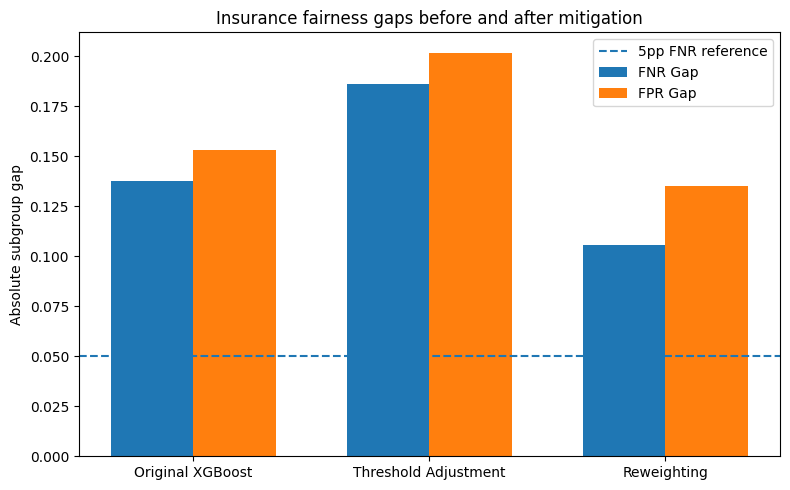

In [40]:
comparison_plot = pd.DataFrame({
  "Strategy": [
    "Original XGBoost",
    "Threshold Adjustment",
    "Reweighting"
  ],
  "FNR Gap": [
    baseline_fnr_gap,
    threshold_adj_gaps["FNR Gap"],
    reweighted_gaps["FNR Gap"]
  ],
  "FPR Gap": [
    baseline_fpr_gap,
    threshold_adj_gaps["FPR Gap"],
    reweighted_gaps["FPR Gap"]
  ]
})

x = np.arange(len(comparison_plot))
width = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
  x - width / 2,
  comparison_plot["FNR Gap"],
  width,
  label="FNR Gap"
)
ax.bar(
  x + width / 2,
  comparison_plot["FPR Gap"],
  width,
  label="FPR Gap"
)

ax.set_xticks(x)
ax.set_xticklabels(comparison_plot["Strategy"])
ax.set_ylabel("Absolute subgroup gap")
ax.set_title("Insurance fairness gaps before and after mitigation")
ax.axhline(
  0.05,
  linestyle="--",
  label="5pp FNR reference"
)
ax.legend()
plt.tight_layout()
plt.show()